# 01 · Bayesian analysis of the raw asymmetry $A_{\rm raw}$ in $B^\pm\to K^\pm K^+K^-$

**What this notebook does.** It fits the $B^\pm$ invariant-mass spectrum with the nominal mass model, samples the
posterior of the raw asymmetry $A_{\rm raw}=(N^--N^+)/(N^-+N^+)$ with MCMC, and derives from the same posterior
the numbers and figures of the Bayesian part of the report: credible intervals, Bayes factor of $A=0$, systematic
uncertainty, toy-MC closure test, behaviour under the two magnet polarities, local asymmetry in the Dalitz plane and
charm vetoes.

**Companion notebooks.** `02_bayes_model_checks_and_priors.ipynb` (posterior predictive checks, convergence, prior
sensitivity, Savage–Dickey) and `03_bayes_vs_frequentist_low_statistics.ipynb` (small samples, six-parameter model).
The model itself, the sampler and the toy generator are in `bayes_model.py`; this notebook only calls them.

### What goes into the report

| Section of this notebook | Report (section → element) |
|---|---|
| 1 Data | *Data → Data exploration*: figure `mass_spectrum`; candidate counts |
| 2 Model | *Mass model and likelihood*; parameter list and priors |
| 3 Nominal fit | *Bayesian analysis → Posterior results*: $A_{\rm raw}$, 68 %/95 % intervals, $\chi^2$, $\tau$ |
| 3 Figures | `bayes_nominal_mass_fit`, `bayes_nominal_corner` |
| 4 Bayes factors | *Bayesian analysis → Bayes factors*; appendix: figure `bayes_nominal_savage_dickey` |
| 5 Systematic study | *Systematics and result*; appendix: figure `syst_variants`, Barlow criterion |
| 6 Toy MC | appendix *Toy-MC coverage validation*: figure `bayes_nominal_toys` |
| 7 Magnet polarity | appendix *Robustness checks*: figure `bayes_nominal_magnet` |
| 8 Dalitz plane | *Local asymmetry in the Dalitz plane*: figure `bayes_nominal_dalitz_maps`, homogeneity tests; appendix: figure `dalitz_permutation` |
| 9 Charm vetoes | appendix *Robustness checks* (informative only) |
| 10 Save | `results/nominal/nominal_summary.json`, read by notebooks 02, 03 and by the ML notebook |

### How to run

* Environment: `environment.yml` at the root of the repository (conda env `cern`); data: `LHCb/opendata-project/Data`.
* **Cost.** The full computation takes about 2 h 20 min on 10 cores (nominal chain 25 000 steps, ~20 further fits,
  200 toys). Every long block writes its results line by line to `results/nominal/*.jsonl` and **resumes** from them:
  running the notebook again with the saved results takes a few minutes and reproduces the numbers and figures.
  To recompute from scratch delete `results/nominal/`.
* All random numbers are generated with fixed seeds.

## 0 · Setup

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace, asdict
from scipy.stats import norm, chi2 as chi2_dist, binom

sys.path.insert(0, ".")        # bayes_model.py
sys.path.insert(0, "..")       # plot_style.py (common figure style)
import bayes_model as bn
import plot_style as ps
ps.use(); C = ps.COLORS

DATA_DIR    = "../../../opendata-project/Data"
RESULTS_DIR = os.path.join(os.getcwd(), "results", "nominal")      # numbers saved by this notebook
FIG_DIR     = os.path.join(os.getcwd(), "figures")                 # figures of the report
for d in (RESULTS_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# MCMC settings (emcee, 4 walkers per parameter; integrated autocorrelation time tau of about 150-185 steps)
NSTEPS     = 25000    # nominal fit and every variation: chain longer than 50 tau for all parameters
N_TOYS     = 200      # pseudo-experiments of the closure test
NSTEPS_TOY = 12000    # chain of each toy: longer than 65 tau after burn-in
N_THINNED  = 20000    # posterior sample kept for the figures
N_WORKERS  = max(1, (os.cpu_count() or 2) - 1)

def save_json(name, obj):
    path = os.path.join(RESULTS_DIR, name)
    with open(path, "w") as f:
        json.dump(obj, f, indent=1)
    print("[saved]", os.path.relpath(path))

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name))
    plt.show()
    print("[saved]", os.path.join("figures", name))

print(f"results -> {os.path.relpath(RESULTS_DIR)}\nfigures -> {os.path.relpath(FIG_DIR)}\nworkers = {N_WORKERS}")

results -> results/nominal
figures -> figures
workers = 9


## 1 · Data and preselection

The record contains $B^\pm\to h^\pm h^+h^-$ candidates from the 2011 data (magnet up and down).
`bn.load_candidates` applies the preselection common to the whole project (muon veto and particle-identification
cuts on the three tracks) and computes, for each candidate, the $KKK$ invariant mass `m`, the charge `q` of the $B$,
the two opposite-sign $K^+K^-$ masses (`m12`, `m13`, used for the Dalitz plane and the charm vetoes) and the magnet
polarity. `bn.select` then applies the fit window of one configuration (here the nominal one, $[5100,5600]$ MeV).

In [2]:
cands    = bn.load_candidates(DATA_DIR)           # all preselected candidates with |q| = 1
data_nom = bn.select(cands, bn.NOMINAL)           # nominal fit window
n_pos, n_neg = int((data_nom.q > 0).sum()), int((data_nom.q < 0).sum())
print(f"preselected candidates (|q|=1): {len(cands)};  in [{bn.NOMINAL.lo:.0f},{bn.NOMINAL.hi:.0f}] MeV: {len(data_nom)}")
print(f"  B+: {n_pos}   B-: {n_neg}   counting asymmetry (N- - N+)/(N- + N+): {(n_neg - n_pos) / len(data_nom):+.4f}")
print(f"  magnet down: {(data_nom.magnet == 'down').sum()}   magnet up: {(data_nom.magnet == 'up').sum()}")

preselected candidates (|q|=1): 37045;  in [5100,5600] MeV: 19731
  B+: 10292   B-: 9439   counting asymmetry (N- - N+)/(N- + N+): -0.0432
  magnet down: 11636   magnet up: 8095


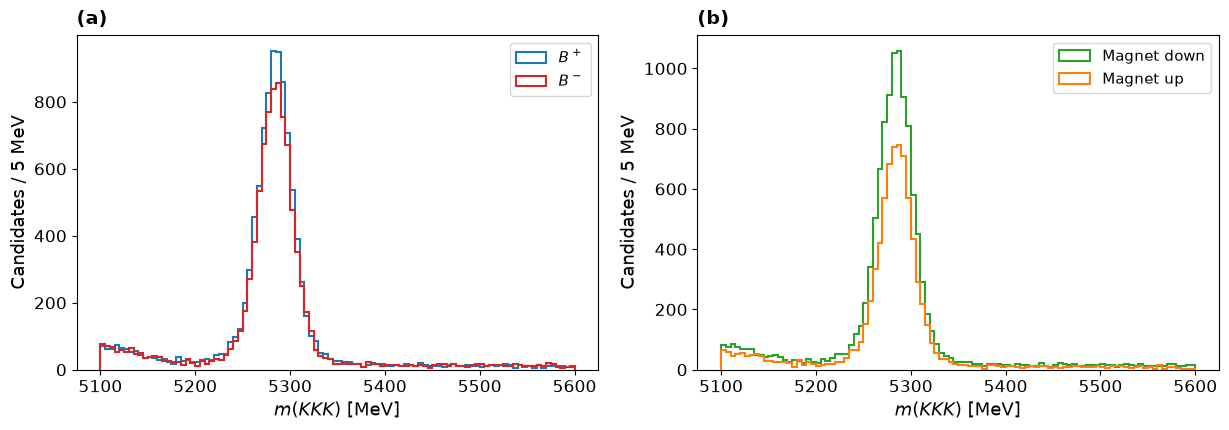

[saved] figures/mass_spectrum.pdf


In [3]:
# Figure `mass_spectrum`: mass spectrum split by B charge and by magnet polarity
bins = np.arange(bn.NOMINAL.lo, bn.NOMINAL.hi + 1e-9, 5.0)
fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.5))
for sel, lab, col in ((data_nom.q > 0, r"$B^+$", C["pos"]), (data_nom.q < 0, r"$B^-$", C["neg"])):
    axs[0].hist(data_nom.m[sel], bins=bins, histtype="step", lw=1.5, color=col, label=lab)
for sel, lab, col in ((data_nom.magnet == "down", "Magnet down", C["down"]), (data_nom.magnet == "up", "Magnet up", C["up"])):
    axs[1].hist(data_nom.m[sel], bins=bins, histtype="step", lw=1.5, color=col, label=lab)
for k, a in enumerate(axs):
    a.set_xlabel(r"$m(KKK)$ [MeV]"); a.set_ylabel("Candidates / 5 MeV"); a.legend(); ps.letter(a, "ab"[k])
plt.tight_layout()
save_fig(fig, "mass_spectrum.pdf")

## 2 · Mass model and priors

Fit window $m\in[5100,5600]$ MeV; extended unbinned likelihood, one term per charge $\pm$:

$$
\ln\mathcal L=\sum_{\pm}\Big[-\nu_\pm+\sum_{i\in\pm}\ln\big(N_s^{\pm}\,S(m_i)+N_b^{\pm}\,B_\pm(m_i)\big)\Big],\qquad
N_s^{\pm}=\tfrac{N_s}{2}(1\mp A),\quad N_b^{\pm}=\tfrac{N_b}{2}(1\mp A_b),
$$

with $\nu_\pm=N_s^\pm+N_b^\pm$. $S$ is a Gaussian (shared $\mu,\sigma$) truncated to the window; $B_\pm$ is a
double exponential $f_\pm\,e^{-\lambda_{1\pm}(m-m_{\rm lo})}+(1-f_\pm)\,e^{-\lambda_{2\pm}(m-m_{\rm lo})}$,
normalised in the window, with a **separate shape for each charge**. The 12 parameters and their priors
(independent and uniform, to make the posterior proportional to the likelihood):

| parameter | meaning | prior |
|---|---|---|
| $N_s$, $N_b$ | signal and background yields | $(0,5n)$, $n$ = number of candidates |
| $A$, $A_b$ | raw asymmetry of signal and of background | $(-1,1)$ |
| $\mu$, $\sigma$ | signal mass and resolution [MeV] | $(5260,5310)$, $(3,40)$ |
| $\lambda_{1\pm},\lambda_{2\pm}$ | background slopes [1/MeV], $\lambda_1>\lambda_2$ | $(10^{-5},0.1)$ |
| $f_\pm$ | weight of the first exponential | $(0,1)$ |

The condition $\lambda_1>\lambda_2$ removes the label-switching symmetry of the two exponentials. The variants used
for the systematic study (window, background, signal, preselection) are `bn.VARIATIONS`; the model and the list are
the same as in the frequentist analysis.

## 3 · Nominal fit: posterior of $A_{\rm raw}$

`bn.fit` maximises the posterior to start the walkers and runs `emcee` (affine-invariant ensemble sampler).
Quantities printed below: the median and the 68 %/95 % equal-tailed credible intervals of $A$, the MAP (equal to the
maximum-likelihood estimate with flat priors, hence directly comparable with the frequentist fit), the $\chi^2$ of
the binned model against the data (10 MeV bins, both charges), the acceptance and the integrated autocorrelation
times $\tau$. The chain must be longer than 50 $\tau$ for every parameter (the cell stops otherwise).

In [4]:
# resume: a finished fit with the same configuration and chain length is loaded instead of recomputed
f_fit = os.path.join(RESULTS_DIR, "nominal_fit.json")
f_th  = os.path.join(RESULTS_DIR, "nominal_posterior_thinned.npy")
prev = json.load(open(f_fit)) if os.path.exists(f_fit) and os.path.exists(f_th) else None
same_cfg = prev is not None and prev["config"] == json.loads(json.dumps(asdict(bn.NOMINAL)))   # tuples -> lists in JSON
if same_cfg and prev["nsteps"] == NSTEPS:
    nominal = dict(prev, _thinned=np.load(f_th))
    print("[resume] nominal fit loaded from", os.path.relpath(f_fit))
else:
    nominal = bn.fit(data_nom.m, data_nom.q, bn.NOMINAL, nsteps=NSTEPS, keep_thinned=N_THINNED)
    np.save(f_th, nominal["_thinned"])
    save_json("nominal_fit.json", bn.to_jsonable(nominal))

A = nominal["A"]
print(f"A_raw = {A['median']:.4f}   68% CI [{A['ci68'][0]:.4f}, {A['ci68'][1]:.4f}]   "
      f"95% CI [{A['ci95'][0]:.4f}, {A['ci95'][1]:.4f}]   sd {A['sd']:.4f}")
print(f"A_b   = {nominal['A_b']['median']:.4f} +- {nominal['A_b']['sd']:.4f}")
print(f"MAP A = {nominal['map']['A']:.4f}   (flat priors: MAP = MLE)")
print(f"chi2/ndof = {nominal['gof']['chi2']:.1f}/{nominal['gof']['ndof']}   p = {nominal['gof']['p']:.1e}")
print(f"acceptance {nominal['acceptance']:.2f};  minimum chain/tau = {nominal['chain_over_tau_min']:.0f}  (must be > 50)")
for k, t in nominal["tau"].items():
    print(f"   tau[{k:9s}] = {t:6.1f}")
assert nominal["chain_over_tau_min"] > 50, "chain too short compared with tau: increase NSTEPS"

[resume] nominal fit loaded from results/nominal/nominal_fit.json
A_raw = -0.0443   68% CI [-0.0528, -0.0358]   95% CI [-0.0608, -0.0276]   sd 0.0085
A_b   = -0.0400 +- 0.0176
MAP A = -0.0441   (flat priors: MAP = MLE)
chi2/ndof = 164.1/88   p = 1.6e-06
acceptance 0.38;  minimum chain/tau = 114  (must be > 50)
   tau[N_s      ] =  148.1
   tau[N_b      ] =  149.0
   tau[A        ] =  149.4
   tau[A_b      ] =  147.4
   tau[mu       ] =  177.3
   tau[sigma    ] =  162.8
   tau[lam1_pos ] =  183.3
   tau[lam2_pos ] =  167.8
   tau[f_pos    ] =  174.0
   tau[lam1_neg ] =  175.3
   tau[lam2_neg ] =  163.7
   tau[f_neg    ] =  171.8


**Figure `bayes_nominal_mass_fit`.** Data, total model, signal and background at the posterior median, for each
charge, with the pulls $(n_i-\nu_i)/\sqrt{\nu_i}$ in 10 MeV bins (log scale in the upper panels).

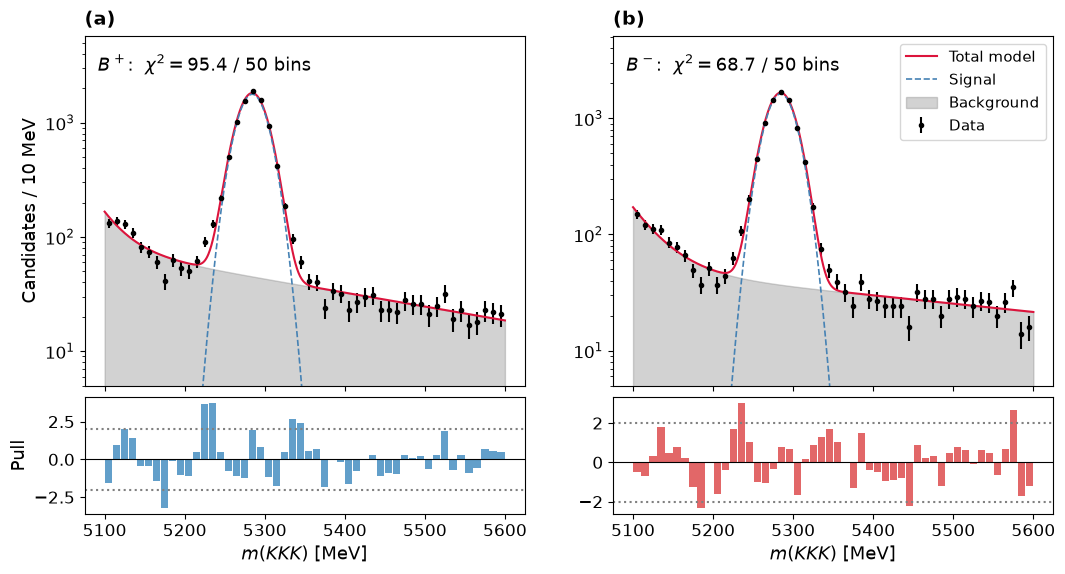

[saved] figures/bayes_nominal_mass_fit.pdf


In [5]:
thinned, names, cfg = nominal["_thinned"], nominal["names"], bn.NOMINAL
post  = bn.Posterior(data_nom.m.to_numpy(), data_nom.q.to_numpy(), cfg)
d_med = post.unpack(np.median(thinned, axis=0))
width = 10.0
edges = np.arange(cfg.lo, cfg.hi + 1e-9, width); cen = 0.5 * (edges[1:] + edges[:-1])
grid  = np.linspace(cfg.lo, cfg.hi, 800)

fig, axs = plt.subplots(2, 2, figsize=(ps.DOUBLE, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05})
for col, (side, sg, lab) in enumerate((("pos", -1, r"$B^+$"), ("neg", +1, r"$B^-$"))):
    msk = post.plus if side == "pos" else ~post.plus
    obs, _ = np.histogram(post.m[msk], edges)
    sig_c = d_med["N_s"] * (1 + sg * d_med["A"])   / 2 * bn._signal_pdf(grid, d_med, cfg) * width
    bkg_c = d_med["N_b"] * (1 + sg * d_med["A_b"]) / 2 * bn._bkg_pdf(grid, d_med, side, cfg) * width
    exp = (d_med["N_s"] * (1 + sg * d_med["A"])   / 2 * bn._signal_pdf(cen, d_med, cfg)
         + d_med["N_b"] * (1 + sg * d_med["A_b"]) / 2 * bn._bkg_pdf(cen, d_med, side, cfg)) * width
    pull = (obs - exp) / np.sqrt(exp)
    a = axs[0, col]
    a.errorbar(cen, obs, yerr=np.sqrt(obs), fmt="o", ms=3, color=C["data"], label="Data")
    a.plot(grid, sig_c + bkg_c, color=C["model"], lw=1.5, label="Total model")
    a.plot(grid, sig_c, color=C["signal"], ls="--", lw=1.2, label="Signal")
    a.fill_between(grid, 0.5, bkg_c, color=C["background"], alpha=0.35, label="Background")
    a.set_yscale("log"); a.set_ylim(5, obs.max() * 3)
    ps.letter(a, "ab"[col]); ps.panel_label(a, f"{lab}:  $\\chi^2 = {np.sum(pull**2):.1f}$ / {len(cen)} bins")
    p = axs[1, col]
    p.bar(cen, pull, width=width * 0.9, color=C[side], alpha=0.7)
    p.axhline(0, color="k", lw=0.8); [p.axhline(y, color="gray", ls=":") for y in (2, -2)]
    p.set_xlabel(r"$m(KKK)$ [MeV]")
axs[0, 0].set_ylabel(f"Candidates / {width:.0f} MeV"); axs[1, 0].set_ylabel("Pull")
axs[0, 1].legend(loc="upper right")
save_fig(fig, "bayes_nominal_mass_fit.pdf")

**Figure `bayes_nominal_corner`.** Joint and marginal posteriors of the six physical parameters (the background
shapes are omitted for readability). Titles: median and 68 % interval from the full chain.

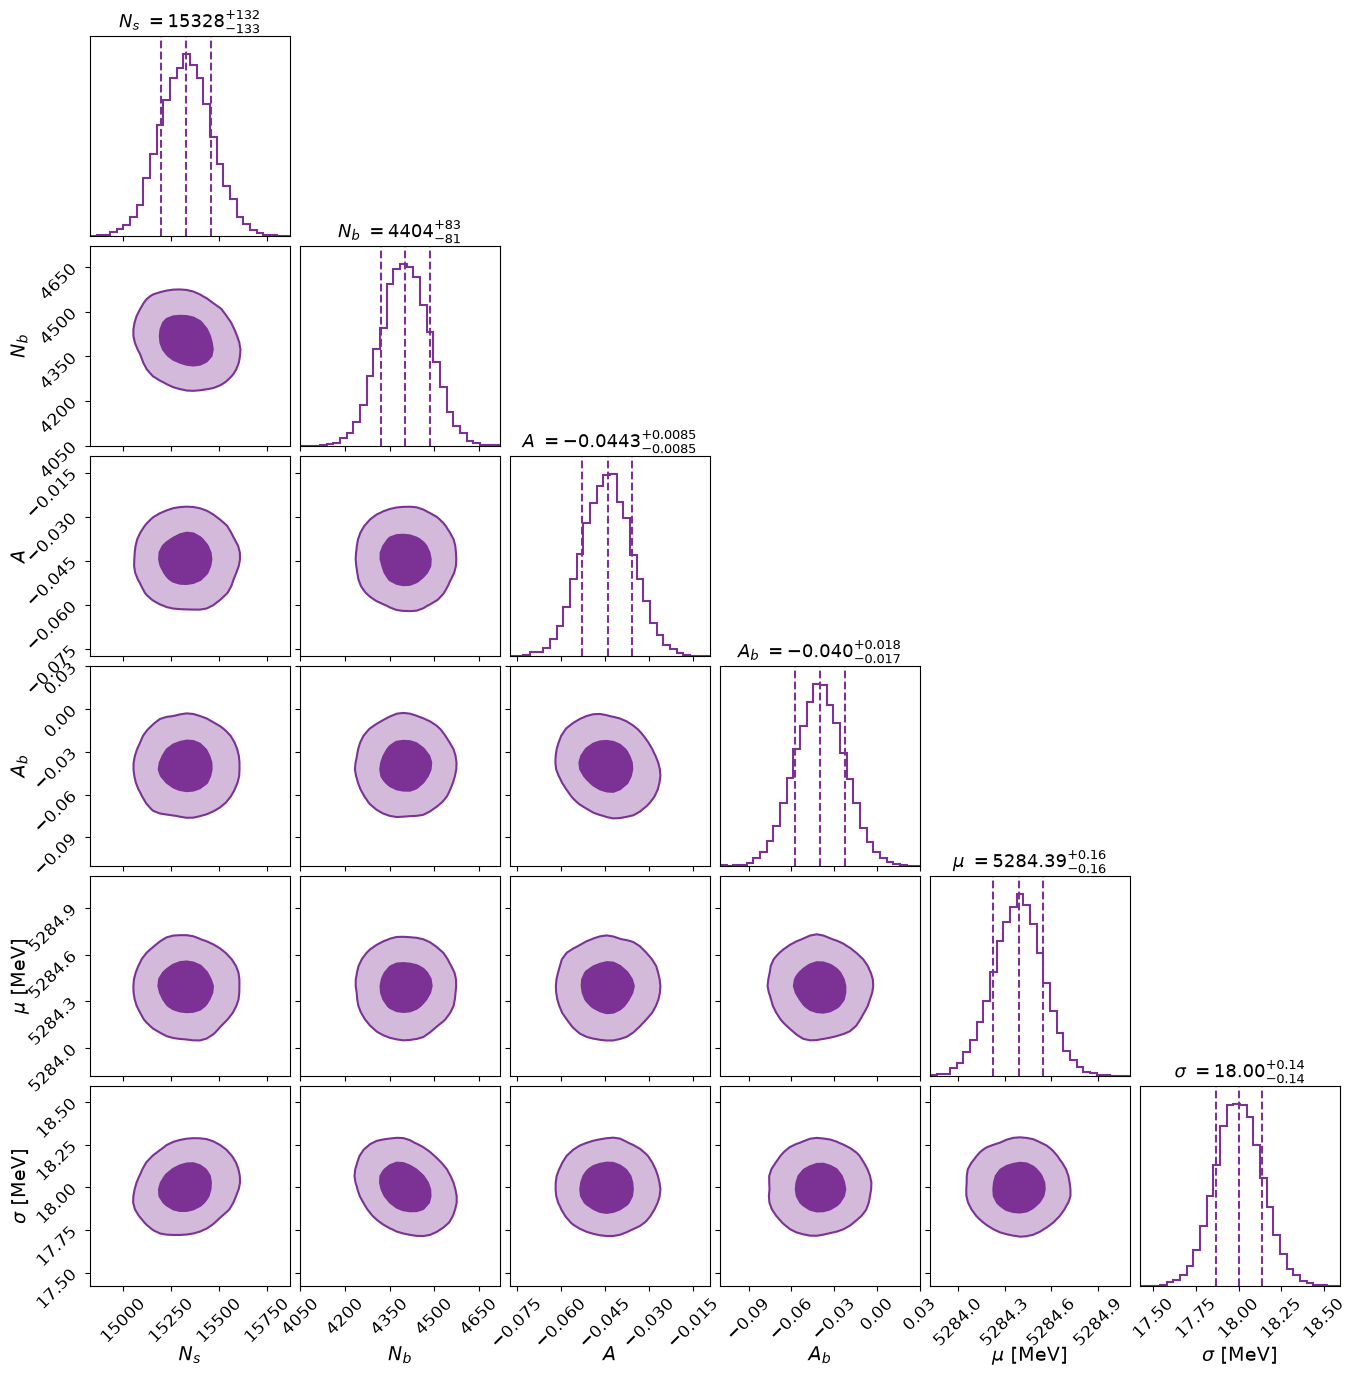

[saved] figures/bayes_nominal_corner.pdf


In [6]:
import corner
main   = ["N_s", "N_b", "A", "A_b", "mu", "sigma"]
labels = [r"$N_s$", r"$N_b$", r"$A$", r"$A_b$", r"$\mu$ [MeV]", r"$\sigma$ [MeV]"]
fmts   = [".0f", ".0f", ".4f", ".3f", ".2f", ".2f"]
th = thinned[:, [names.index(k) for k in main]]
fig = corner.corner(th, labels=labels, quantiles=[0.16, 0.5, 0.84], show_titles=False, plot_datapoints=False,
                    color=C["bayes"], levels=1 - np.exp(-0.5 * np.array([1.0, 2.0]) ** 2), smooth=1.0,
                    fill_contours=True, plot_density=False, bins=30, label_kwargs={"fontsize": 14},
                    hist_kwargs={"color": C["bayes"], "lw": 1.5})
ax = np.array(fig.axes).reshape(len(main), len(main))
for k in range(len(main)):
    st = nominal[main[k]]; q50 = st["median"]; q16, q84 = st["ci68"]; f = fmts[k]
    ax[k, k].set_title(f"{labels[k].split(' [')[0]} $= {q50:{f}}^{{+{q84-q50:{f}}}}_{{-{q50-q16:{f}}}}$", fontsize=13)
for a_ in fig.axes:        # plain tick labels (no "+5.284e3" offset on the mu axis)
    for axis in (a_.xaxis, a_.yaxis):
        fmt = axis.get_major_formatter()
        if hasattr(fmt, "set_useOffset"):
            fmt.set_useOffset(False)
save_fig(fig, "bayes_nominal_corner.pdf")

## 4 · Bayes factors (Savage–Dickey)

The models $\mathcal M_0:A=0$ and $\mathcal M_1:A\neq0$ (uniform prior on $(-1,1)$, prior density $1/2$) are nested,
so the Bayes factor is the ratio of the posterior to the prior density at the null value (Savage–Dickey):
$\mathrm{BF}_{01}=p(A=0\mid{\rm data})/\pi(A=0)$. The posterior density at 0 is evaluated with the Gaussian
approximation of the marginal posterior (the null value is far in the tail, where a histogram of the chain is empty);
the same for $A_b=0$. Equal prior odds. The robustness to the prior width and the check of the Gaussian approximation
are in notebook 02.

**Figure `bayes_nominal_savage_dickey`.** Marginal posterior (histogram), its Gaussian approximation, and the prior
density; the points mark the two densities at the null value, whose ratio is $\mathrm{BF}_{01}$.

A   = 0 : BF_01 = 1.14e-04   BF_10 = 8.81e+03   (5.2 sd from zero)
A_b = 0 : BF_01 = 3.45   BF_10 = 0.29   (2.3 sd from zero)


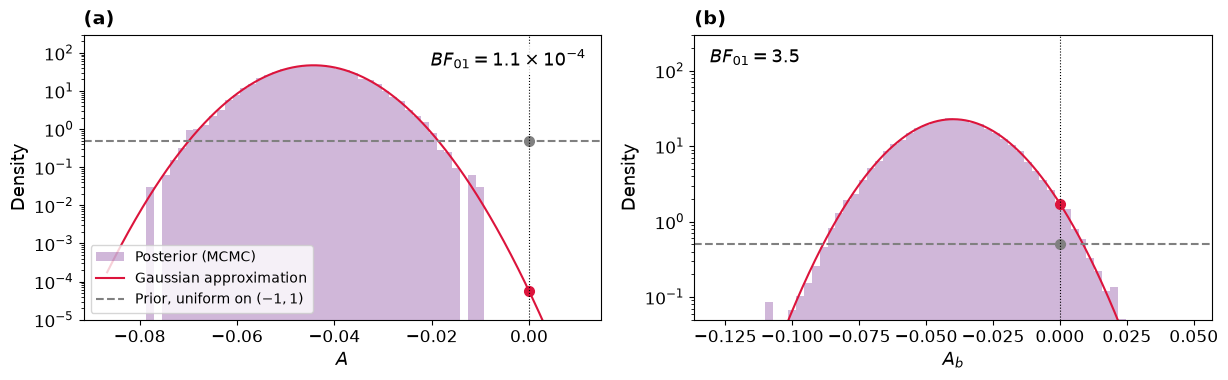

[saved] figures/bayes_nominal_savage_dickey.pdf


In [7]:
bf_A  = bn.bayes_factor_gaussian(nominal, "A",   1 / bn.prior_volume_A(bn.NOMINAL))
bf_Ab = bn.bayes_factor_gaussian(nominal, "A_b", 0.5)
print(f"A   = 0 : BF_01 = {bf_A:.2e}   BF_10 = {1/bf_A:.2e}   ({abs(A['mean'])/A['sd']:.1f} sd from zero)")
print(f"A_b = 0 : BF_01 = {bf_Ab:.2f}   BF_10 = {1/bf_Ab:.2f}   ({abs(nominal['A_b']['mean'])/nominal['A_b']['sd']:.1f} sd from zero)")

fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.0))
for a, par, lab in ((axs[0], "A", r"$A$"), (axs[1], "A_b", r"$A_b$")):
    x = thinned[:, names.index(par)]; m_, s_ = nominal[par]["mean"], nominal[par]["sd"]
    lo_, hi_ = min(-0.01, m_ - 5 * s_), max(0.01, m_ + 5 * s_)
    a.hist(x, bins=60, range=(lo_, hi_), density=True, histtype="stepfilled", color=C["bayes"], alpha=0.35, label="Posterior (MCMC)")
    ps.letter(a, "a" if par == "A" else "b")
    xs = np.linspace(lo_, hi_, 600)
    a.plot(xs, norm.pdf(xs, m_, s_), color=C["model"], lw=1.5, label="Gaussian approximation")
    a.axhline(0.5, color=C["background"], ls="--", lw=1.5, label=r"Prior, uniform on $(-1,1)$")
    p0 = norm.pdf(0.0, m_, s_)
    a.plot([0], [p0], "o", color=C["model"], ms=7); a.plot([0], [0.5], "o", color=C["background"], ms=7)
    a.axvline(0, color="k", ls=":", lw=0.8)
    a.set_yscale("log"); a.set_ylim(1e-5 if par == "A" else 0.05, 300)
    a.set_xlabel(lab); a.set_ylabel("Density")
    bf = p0 / 0.5
    ps.panel_label(a, f"$BF_{{01}}={ps.sci(bf)}$" if bf < 0.01 else f"$BF_{{01}}={bf:.1f}$",
                   loc="upper right" if par == "A" else "upper left")
axs[0].legend(loc="lower left", fontsize=10)
plt.tight_layout()
save_fig(fig, "bayes_nominal_savage_dickey.pdf")

## 5 · Fits of the variants, systematic uncertainty and checks (in parallel)

One batch of independent fits, each with the same chain length as the nominal one (about 20 fits, the bulk of the
computing time; checkpoint in `results/nominal/fits.jsonl`):

* two fits with the walkers spread over the whole prior box (dispersed start): the chain must converge to the same
  posterior (trace plots in notebook 02);
* the two magnet-polarity samples (cross-check, **not** a systematic);
* the 13 variants of the systematic study, `bn.VARIATIONS` (window, background model, signal model, preselection);
* a prior check, $A\in(-0.3,0.3)$ (Bayesian only, not a systematic);
* the two charm vetoes (section 9, informative only).

In [8]:
fit_tasks = []
for s in (1, 2):      # dispersed start
    fit_tasks.append((replace(bn.NOMINAL, name=f"dispersed_{s}"), data_nom.m.to_numpy(), data_nom.q.to_numpy(), NSTEPS, s, True))
for pol in ("down", "up"):     # magnet polarities
    d = data_nom[data_nom.magnet == pol]
    fit_tasks.append((replace(bn.NOMINAL, name=f"magnet_{pol}"), d.m.to_numpy(), d.q.to_numpy(), NSTEPS, 42, False,
                      os.path.join(RESULTS_DIR, f"magnet_{pol}_A_thinned.npy")))
for c in bn.VARIATIONS + bn.PRIOR_CHECKS + bn.CHARM_VETOES:     # variants, prior check, vetoes
    d = bn.select(cands, c)
    fit_tasks.append((c, d.m.to_numpy(), d.q.to_numpy(), NSTEPS, 42, False))

fits = bn.run_parallel(fit_tasks, bn._fit_task, os.path.join(RESULTS_DIR, "fits.jsonl"),
                       key=lambda r: r["config"]["name"], n_workers=N_WORKERS)
fits = {r["config"]["name"]: r for r in fits}
for name, r in fits.items():
    print(f"{name:22s} n={r['n']:6d}  A={r['A']['median']:+.4f} [{r['A']['ci68'][0]:+.4f},{r['A']['ci68'][1]:+.4f}]  "
          f"dA={r['A']['median']-A['median']:+.4f}  chi2/ndof={r['gof']['chi2']:.0f}/{r['gof']['ndof']}  "
          f"chain/tau={r['chain_over_tau_min']:.0f}" + (f"  bulk after {r['steps_to_bulk']} steps" if r.get('dispersed') else ""))

results/nominal/fits.jsonl: 20 already done, 0 to run


dispersed_1            n= 19731  A=-0.0446 [-0.0529,-0.0360]  dA=-0.0003  chi2/ndof=164/88  chain/tau=72  bulk after 1158 steps
dispersed_2            n= 19731  A=-0.0442 [-0.0528,-0.0356]  dA=+0.0001  chi2/ndof=164/88  chain/tau=68  bulk after 2588 steps
magnet_down            n= 11636  A=-0.0497 [-0.0607,-0.0386]  dA=-0.0054  chi2/ndof=153/88  chain/tau=81
magnet_up              n=  8095  A=-0.0378 [-0.0507,-0.0251]  dA=+0.0065  chi2/ndof=150/88  chain/tau=77
window_lo5050          n= 21164  A=-0.0446 [-0.0531,-0.0362]  dA=-0.0003  chi2/ndof=217/98  chain/tau=51
window_lo5150          n= 18566  A=-0.0444 [-0.0528,-0.0359]  dA=-0.0001  chi2/ndof=142/78  chain/tau=10
window_hi5450          n= 19004  A=-0.0440 [-0.0524,-0.0357]  dA=+0.0002  chi2/ndof=137/58  chain/tau=103
window_hi5700          n= 20191  A=-0.0456 [-0.0540,-0.0373]  dA=-0.0014  chi2/ndof=200/108  chain/tau=81
bkg_single_exp         n= 19731  A=-0.0480 [-0.0564,-0.0395]  dA=-0.0037  chi2/ndof=298/92  chain/tau=210
bkg_sh

**Systematic uncertainty.** For each variant the shift $\Delta=A^{\rm var}-A^{\rm nom}$ is compared with the
Barlow criterion $\sigma_B=\sqrt{|\sigma_{\rm var}^2-\sigma_{\rm nom}^2|}$ (for variants that change the sample, the
statistical fluctuation between nested samples): a shift enters only if $|\Delta|>\sigma_B$ (`counts`). Variants
rejected by the data (goodness of fit) are excluded. Within a group the largest counting shift is taken; the groups
are added in quadrature (`syst["rule"]`). The prior check is not part of the systematic uncertainty.

In [9]:
syst = bn.systematics(nominal, [fits[c.name] for c in bn.VARIATIONS])
for k, v in syst["variations"].items():
    sb = "-" if v["sigma_barlow"] is None else f"{v['sigma_barlow']:.4f}"
    print(f"{k:22s} shift={v['shift']:+.4f}  sigma_B={sb:>7s}  "
          f"{'EXCLUDED (data)' if v['rejected_by_data'] else ('counts' if v['counts'] else 'does not count (Barlow)')}")
print("by group   :", {k: round(v, 4) for k, v in syst["groups"].items()})
print(f"total systematic ({syst['rule']}): {syst['total']:.4f}   vs statistical {A['sd']:.4f}")
pc = fits["prior_A_narrow"]
print(f"prior check (A in (-0.3, 0.3), not in the systematic): A = {pc['A']['median']:.4f} (shift {pc['A']['median'] - A['median']:+.4f})")

window_lo5050          shift=-0.0003  sigma_B= 0.0009  does not count (Barlow)
window_lo5150          shift=-0.0001  sigma_B= 0.0007  does not count (Barlow)
window_hi5450          shift=+0.0002  sigma_B= 0.0009  does not count (Barlow)
window_hi5700          shift=-0.0014  sigma_B= 0.0010  counts
bkg_single_exp         shift=-0.0037  sigma_B=      -  EXCLUDED (data)
bkg_shared_shape       shift=-0.0037  sigma_B=      -  counts
bkg_symmetric          shift=-0.0028  sigma_B=      -  counts
signal_crystal_ball    shift=-0.0002  sigma_B=      -  counts
signal_per_charge      shift=-0.0000  sigma_B=      -  counts
presel_probk_0.4       shift=-0.0032  sigma_B= 0.0038  does not count (Barlow)
presel_probk_0.6       shift=+0.0058  sigma_B= 0.0048  counts
presel_probpi_0.4      shift=+0.0022  sigma_B= 0.0022  counts
presel_probpi_0.6      shift=-0.0004  sigma_B= 0.0020  does not count (Barlow)
by group   : {'window': 0.0014, 'background': 0.0037, 'signal': 0.0002, 'preselection': 0.0058}
tota

**Figure `syst_variants`.** Shift of every variant for the Bayesian analysis (this notebook) and for the frequentist
one (`results/external/freq_systematics.json`, copied from the frequentist analysis), with the Barlow uncertainty
$\sigma_B$ as error bar; an open symbol marks a variant rejected by the data.

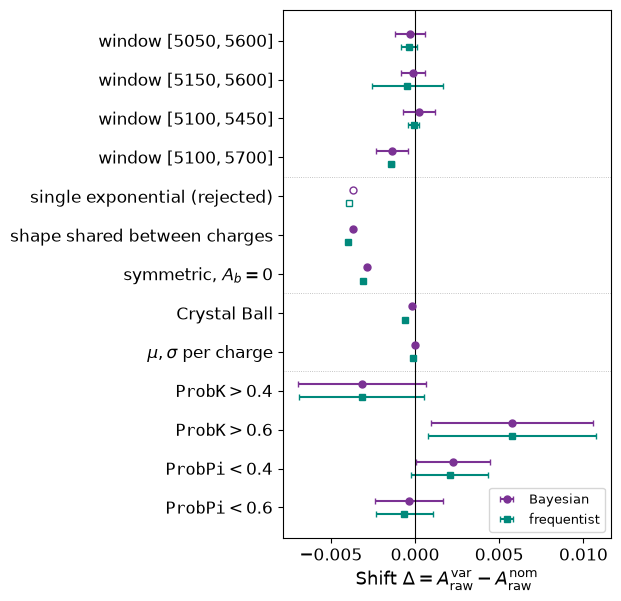

[saved] figures/syst_variants.pdf


In [10]:
freq_file = os.path.join("results", "external", "freq_systematics.json")
bs = syst["variations"]
fs = json.load(open(freq_file))["systematics"]["variations"] if os.path.exists(freq_file) else None
LAB = [("window_lo5050", "window $[5050,5600]$"), ("window_lo5150", "window $[5150,5600]$"),
       ("window_hi5450", "window $[5100,5450]$"), ("window_hi5700", "window $[5100,5700]$"),
       ("bkg_single_exp", "single exponential (rejected)"), ("bkg_shared_shape", "shape shared between charges"),
       ("bkg_symmetric", r"symmetric, $A_b=0$"), ("signal_crystal_ball", "Crystal Ball"),
       ("signal_per_charge", r"$\mu,\sigma$ per charge"), ("presel_probk_0.4", r"$\mathtt{ProbK}>0.4$"),
       ("presel_probk_0.6", r"$\mathtt{ProbK}>0.6$"), ("presel_probpi_0.4", r"$\mathtt{ProbPi}<0.4$"),
       ("presel_probpi_0.6", r"$\mathtt{ProbPi}<0.6$")]
fig, ax = plt.subplots(figsize=(ps.SINGLE, 6.2))
y = np.arange(len(LAB))[::-1]
series = [(bs, C["bayes"], 0.17, "o", "Bayesian")] + ([(fs, C["freq"], -0.17, "s", "frequentist")] if fs else [])
for k, (key, lab) in enumerate(LAB):
    for dd, col, off, mk, name in series:
        v = dd[key]; sb = v.get("sigma_barlow")
        ax.errorbar(v["shift"], y[k] + off, xerr=sb if sb else None, fmt=mk, color=col, ms=5, capsize=2.5,
                    mfc=col if not v.get("rejected_by_data") else "none", label=name if k == 0 else None)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels([l for _, l in LAB])
for yy in (y[3] - 0.5, y[6] - 0.5, y[8] - 0.5):
    ax.axhline(yy, color="0.7", lw=0.6, ls=":")
ax.set_xlabel(r"Shift $\Delta=A_{\mathrm{raw}}^{\mathrm{var}}-A_{\mathrm{raw}}^{\mathrm{nom}}$")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_fig(fig, "syst_variants.pdf")

## 6 · Toy MC: closure test of the procedure

Pseudo-datasets are generated from the nominal model with the parameters at their posterior medians (same number of
events: Poisson fluctuation of the yields) and each is refitted with the same model and the same MCMC settings.
It measures bias, spread and **coverage** of the credible intervals when the model is true; it does not test
whether the model describes the data (posterior predictive check, notebook 02).

**Figure `bayes_nominal_toys`.** (a) pull $(\hat A-A_{\rm true})/\sigma(\hat A)$ against the standard normal;
(b) observed coverage of the 68 % and 95 % intervals against the nominal level.

results/nominal/toys.jsonl: 200 already done, 0 to run


{
 "n_toys": 200,
 "coverage_68": 0.65,
 "coverage_95": 0.93,
 "coverage_68_err": 0.03298484500494128,
 "coverage_95_err": 0.015411035007422441,
 "bias": -0.00023816884331041843,
 "bias_err": 0.0006242096863910885,
 "sd_estimates": 0.008827658042589339,
 "posterior_sd_data": 0.008481356527370304,
 "chain_over_tau_min_worst": 21.5828922452869
}


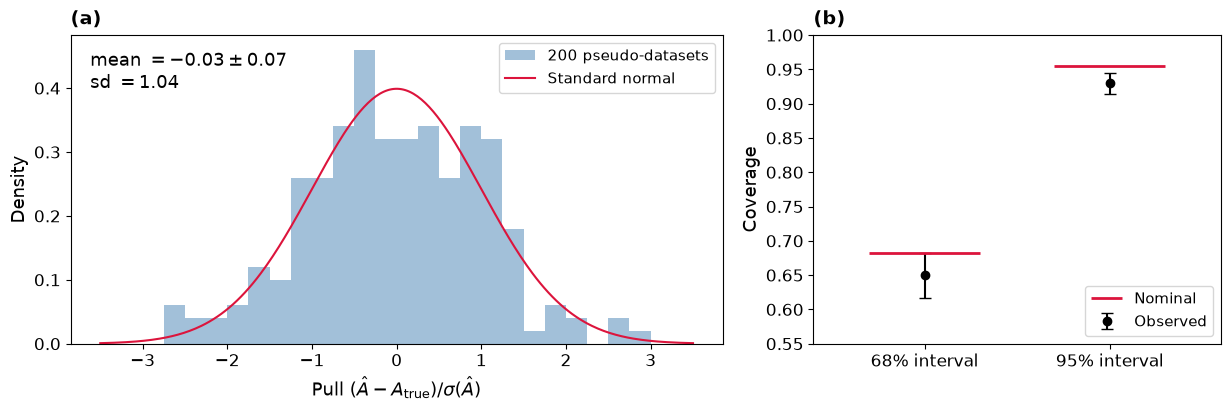

[saved] figures/bayes_nominal_toys.pdf


In [11]:
theta_true = {k: nominal[k]["median"] for k in nominal["names"]}
toy_tasks  = [(i, theta_true, bn.NOMINAL, NSTEPS_TOY, 1000 + i) for i in range(N_TOYS)]
toys = bn.run_parallel(toy_tasks, bn._toy_task, os.path.join(RESULTS_DIR, "toys.jsonl"),
                       key=lambda r: r["toy"], n_workers=N_WORKERS, log_every=10)
cov = bn.coverage_summary(toys, theta_true["A"], A["sd"])
print(json.dumps(cov, indent=1))

a_true = theta_true["A"]
pull = np.array([(t["A_median"] - a_true) / t["A_sd"] for t in toys])
fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
a = axs[0]
a.hist(pull, bins=np.linspace(-3.5, 3.5, 29), density=True, histtype="stepfilled", color=C["replica"], alpha=0.5,
       label=f"{len(pull)} pseudo-datasets")
xs = np.linspace(-3.5, 3.5, 300)
a.plot(xs, norm.pdf(xs), color=C["model"], lw=1.5, label="Standard normal")
a.set_xlabel(r"Pull $(\hat A - A_{\mathrm{true}})/\sigma(\hat A)$"); a.set_ylabel("Density")
ps.panel_label(a, f"mean $= {pull.mean():+.2f}\\pm{pull.std(ddof=1)/np.sqrt(len(pull)):.2f}$\nsd $= {pull.std(ddof=1):.2f}$")
a.legend(loc="upper right"); ps.letter(a, "a")
a = axs[1]; ps.letter(a, "b")
for x, nomcov, key in ((0, 0.6827, "coverage_68"), (1, 0.9545, "coverage_95")):
    a.errorbar([x], [cov[key]], yerr=[cov[key + "_err"]], fmt="o", color=C["data"], capsize=4, label="Observed" if x == 0 else None)
    a.hlines(nomcov, x - 0.3, x + 0.3, color=C["model"], lw=2, label="Nominal" if x == 0 else None)
a.set_xticks([0, 1]); a.set_xticklabels(["68% interval", "95% interval"]); a.set_xlim(-0.6, 1.6)
a.set_ylabel("Coverage"); a.set_ylim(0.55, 1.0); a.legend(loc="lower right")
plt.tight_layout()
save_fig(fig, "bayes_nominal_toys.pdf")

## 7 · The two magnet polarities

The detector asymmetries change sign with the magnet polarity, so the two samples are fitted separately (fits of
section 5). If the effect were a detector artefact it would flip sign; here both polarities give a negative $A$
compatible with each other and with the combination.

**Figure `bayes_nominal_magnet`.** Posterior of $A_{\rm raw}$ for magnet down, magnet up and the combined sample.

magnet down: n=11636  A = -0.0497  68% CI [-0.0607, -0.0386]
magnet up  : n=8095  A = -0.0378  68% CI [-0.0507, -0.0251]


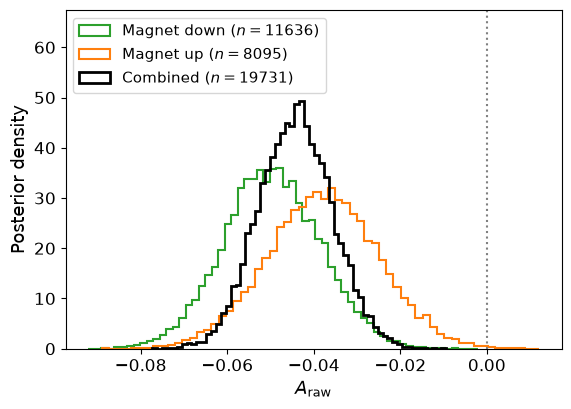

[saved] figures/bayes_nominal_magnet.pdf


In [12]:
mag = {p: np.load(os.path.join(RESULTS_DIR, f"magnet_{p}_A_thinned.npy")) for p in ("down", "up")}
for p in ("down", "up"):
    r = fits[f"magnet_{p}"]
    print(f"magnet {p:4s}: n={r['n']}  A = {r['A']['median']:+.4f}  68% CI [{r['A']['ci68'][0]:+.4f}, {r['A']['ci68'][1]:+.4f}]")
fig, a = plt.subplots(figsize=(ps.SINGLE, 4.4))
for pol in ("down", "up"):
    a.hist(mag[pol], bins=60, density=True, histtype="step", lw=1.5, color=C[pol], label=f"Magnet {pol} ($n={fits[f'magnet_{pol}']['n']}$)")
a.hist(thinned[:, names.index("A")], bins=60, density=True, histtype="step", color="k", lw=2, label=f"Combined ($n={nominal['n']}$)")
a.axvline(0, color="gray", ls=":")
a.set_xlabel(r"$A_{\mathrm{raw}}$"); a.set_ylabel("Posterior density")
a.set_ylim(0, a.get_ylim()[1] * 1.3); a.legend(loc="upper left")
save_fig(fig, "bayes_nominal_magnet.pdf")

## 8 · Local asymmetry in the Dalitz plane

Counting analysis in the $(m^2_{\rm lo},m^2_{\rm hi})$ plane of the two opposite-sign $K^+K^-$ pairs, fixed
$8\times8$ binning (bins with fewer than 20 candidates are discarded). In bin $i$ the asymmetry
$A_i=(n_i^--n_i^+)/n_i$ is compared with the global one $A_{\rm glob}$ through
$S_i=(A_i-A_{\rm glob})/\sqrt{(1-A_i^2)/n_i}$. Two tests: the number of bins with $|S_i|>3$ (and the binomial
probability of seeing at least that many if the asymmetry were uniform) and the homogeneity statistic
$\chi^2=\sum_iS_i^2$ with (number of bins $-1$) degrees of freedom. The test is repeated in the signal window
($|m-\mu|<2\sigma$, where background is small) and after the charm vetoes. Null tests of the procedure (phase-space
permutation, charge permutation) are below and in the appendix.

In [13]:
def dalitz_test(d, label, min_events=20):
    lo2, hi2 = (np.minimum(d.m12, d.m13) / 1e3) ** 2, (np.maximum(d.m12, d.m13) / 1e3) ** 2     # GeV^2
    q = d.q.to_numpy(); ag = (np.sum(q < 0) - np.sum(q > 0)) / len(q)
    el, eh = np.linspace(0, 16, 9), np.linspace(0, 30, 9)
    npl, _, _ = np.histogram2d(lo2[q > 0], hi2[q > 0], [el, eh]); nmi, _, _ = np.histogram2d(lo2[q < 0], hi2[q < 0], [el, eh])
    n = npl + nmi; k = n >= min_events
    ai = (nmi - npl)[k] / n[k]; s = (ai - ag) / np.sqrt((1 - ai ** 2) / n[k])
    c2 = float(np.sum(s ** 2)); nd = int(k.sum() - 1); nsig = int(np.sum(np.abs(s) > 3))
    out = {"label": label, "n": int(len(q)), "A_glob": float(ag), "bins_populated": int(k.sum()), "bins_3sigma": nsig,
           "chi2": c2, "ndof": nd, "p": float(chi2_dist.sf(c2, nd)),
           "p_at_least_nsig_if_uniform": float(binom.sf(nsig - 1, int(k.sum()), 2 * 0.00135)) if nsig else 1.0}
    print(f"{label:28s} n={out['n']:6d} A_glob={ag:+.4f}  {nsig}/{k.sum()} bins |S|>3  chi2={c2:.1f}/{nd}  p={out['p']:.1e}")
    return out

mu_n, sg_n = nominal["mu"]["median"], nominal["sigma"]["median"]
dalitz = [dalitz_test(data_nom, "nominal window"),
          dalitz_test(data_nom[np.abs(data_nom.m - mu_n) < 2 * sg_n], "signal window"),
          dalitz_test(bn.select(cands, bn.CHARM_VETOES[0]), "veto D0"),
          dalitz_test(bn.select(cands, bn.CHARM_VETOES[1]), "veto D0, J/psi, chi_c0")]

nominal window               n= 19731 A_glob=-0.0432  2/32 bins |S|>3  chi2=80.8/31  p=2.6e-06
signal window                n= 15130 A_glob=-0.0461  3/29 bins |S|>3  chi2=95.6/28  p=2.6e-09
veto D0                      n= 18744 A_glob=-0.0464  2/32 bins |S|>3  chi2=79.2/31  p=4.2e-06


veto D0, J/psi, chi_c0       n= 16367 A_glob=-0.0426  1/32 bins |S|>3  chi2=74.4/31  p=2.0e-05


**Figure `bayes_nominal_dalitz_maps`.** (a) candidates per bin; (b) asymmetry $A_i$ per bin; (c) significance $S_i$
with respect to the global asymmetry (bins with $|S_i|>3$ boxed). Dashed lines: $m^2$ of the charm resonances
$D^0$, $J/\psi$, $\chi_{c0}$ (world averages), which appear as vertical and horizontal bands.

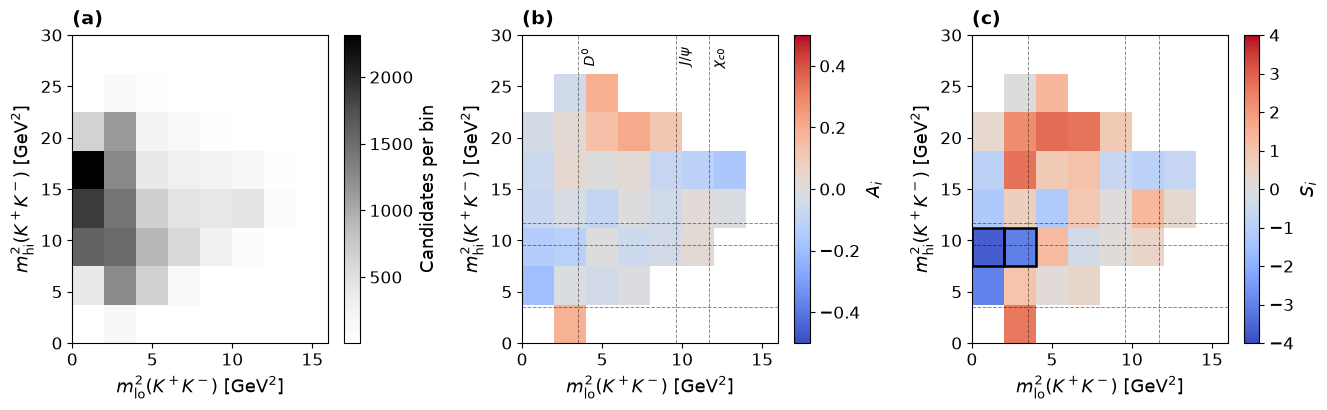

[saved] figures/bayes_nominal_dalitz_maps.pdf


In [14]:
from matplotlib.patches import Rectangle
d = data_nom
lo2, hi2 = (np.minimum(d.m12, d.m13) / 1e3) ** 2, (np.maximum(d.m12, d.m13) / 1e3) ** 2
q = d.q.to_numpy(); ag = (np.sum(q < 0) - np.sum(q > 0)) / len(q)
el, eh = np.linspace(0, 16, 9), np.linspace(0, 30, 9)
npl, _, _ = np.histogram2d(lo2[q > 0], hi2[q > 0], [el, eh]); nmi, _, _ = np.histogram2d(lo2[q < 0], hi2[q < 0], [el, eh])
n = npl + nmi; ok = n >= 20
with np.errstate(divide="ignore", invalid="ignore"):
    ai = np.where(ok, (nmi - npl) / n, np.nan); sg = (ai - ag) / np.sqrt((1 - ai ** 2) / n)
ext = [0, 16, 0, 30]
fig, axs = plt.subplots(1, 3, figsize=(ps.TRIPLE, 4.3))
plt.colorbar(axs[0].imshow(np.where(n > 0, n, np.nan).T, origin="lower", aspect="auto", extent=ext, cmap="Greys"), ax=axs[0], label="Candidates per bin")
plt.colorbar(axs[1].imshow(ai.T, origin="lower", aspect="auto", extent=ext, cmap="coolwarm", vmin=-0.5, vmax=0.5), ax=axs[1], label=r"$A_i$")
plt.colorbar(axs[2].imshow(sg.T, origin="lower", aspect="auto", extent=ext, cmap="coolwarm", vmin=-4, vmax=4), ax=axs[2], label=r"$S_i$")
for i_ in range(len(el) - 1):
    for j_ in range(len(eh) - 1):
        if ok[i_, j_] and abs(sg[i_, j_]) > 3:
            axs[2].add_patch(Rectangle((el[i_], eh[j_]), el[i_ + 1] - el[i_], eh[j_ + 1] - eh[j_], fill=False, ec="k", lw=1.8))
charm = {r"$D^0$": 1.86484, r"$J/\psi$": 3.0969, r"$\chi_{c0}$": 3.4147}          # GeV, world averages
for a in axs[1:]:
    for mval in charm.values():
        a.axvline(mval ** 2, color="k", ls="--", lw=0.7, alpha=0.45); a.axhline(mval ** 2, color="k", ls="--", lw=0.7, alpha=0.45)
for lab_, mval in charm.items():
    axs[1].text(mval ** 2 + 0.2, 28.8, lab_, fontsize=10, va="top", rotation=90)
for k_, a in enumerate(axs):
    a.set_xlabel(r"$m^2_{\mathrm{lo}}(K^+K^-)$ [GeV$^2$]"); a.set_ylabel(r"$m^2_{\mathrm{hi}}(K^+K^-)$ [GeV$^2$]"); ps.letter(a, "abc"[k_])
plt.tight_layout()
save_fig(fig, "bayes_nominal_dalitz_maps.pdf")

**Null test by charge permutation (figure `dalitz_permutation`).** Shuffling the charge labels among the candidates
destroys any real local asymmetry while keeping the Dalitz distribution: the homogeneity statistic must then follow a
$\chi^2$ with (bins $-1$) degrees of freedom. The observed value is far in the tail of the permutation distribution.

observed chi2 = 80.8 (32 bins);  permutations: mean 31.5, sd 8.4, max 72.0, fraction >= observed: 0.0000


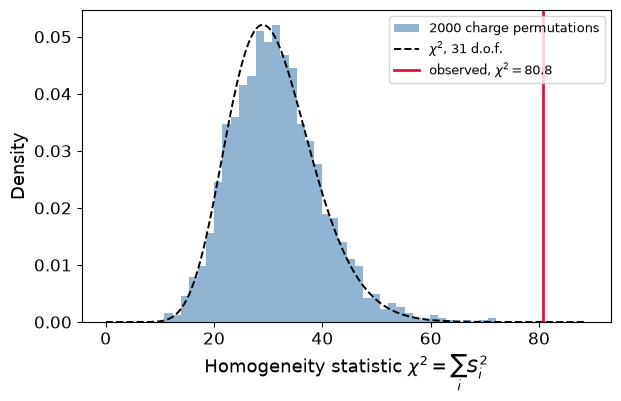

[saved] figures/dalitz_permutation.pdf


In [15]:
from scipy import stats
qv_all = data_nom.q.to_numpy()
m12, m13 = data_nom.m12.to_numpy() ** 2 / 1e6, data_nom.m13.to_numpy() ** 2 / 1e6      # GeV^2
lo, hi = np.minimum(m12, m13), np.maximum(m12, m13)
cell = np.clip((lo / 16 * 8).astype(int), 0, 7) * 8 + np.clip((hi / 30 * 8).astype(int), 0, 7)

def chi2_homog(qv):
    A_glob = (qv == -1).mean() - (qv == 1).mean()
    n_ = np.bincount(cell, minlength=64).astype(float)
    nm = np.bincount(cell[qv == -1], minlength=64).astype(float)
    ok_ = n_ >= 20
    Ai = np.where(ok_, (nm - (n_ - nm)) / np.maximum(n_, 1), 0)
    s_ = np.sqrt(np.clip(1 - Ai ** 2, 1e-9, None) / np.maximum(n_, 1))
    return float((((Ai - A_glob) / s_) ** 2)[ok_].sum()), int(ok_.sum())

obs, nb = chi2_homog(qv_all)
rng = np.random.default_rng(20261012)
perm = np.array([chi2_homog(rng.permutation(qv_all))[0] for _ in range(2000)])
print(f"observed chi2 = {obs:.1f} ({nb} bins);  permutations: mean {perm.mean():.1f}, sd {perm.std():.1f}, max {perm.max():.1f}, "
      f"fraction >= observed: {(perm >= obs).mean():.4f}")
fig, ax = plt.subplots(figsize=(ps.SINGLE, 4.2))
ax.hist(perm, bins=40, density=True, color=C["replica"], alpha=0.6, label="2000 charge permutations")
xs = np.linspace(0, max(obs * 1.1, perm.max() * 1.1), 400)
ax.plot(xs, stats.chi2.pdf(xs, nb - 1), color="k", ls="--", lw=1.4, label=r"$\chi^2$, %d d.o.f." % (nb - 1))
ax.axvline(obs, color=C["observed"], lw=2, label=r"observed, $\chi^2=%.1f$" % obs)
ax.set_xlabel(r"Homogeneity statistic $\chi^2=\sum_iS_i^2$"); ax.set_ylabel("Density"); ax.legend(fontsize=9, loc="upper right")
plt.tight_layout()
save_fig(fig, "dalitz_permutation.pdf")

## 9 · Charm vetoes (informative)

$B^\pm\to D^0K^\pm$, $J/\psi K^\pm$, $\chi_{c0}K^\pm$ with the resonance decaying to $K^+K^-$ are not charmless
decays. A candidate is rejected if at least one of its two opposite-sign $K^+K^-$ pairs lies inside the window
(world-average masses; $\pm30$ MeV for $D^0$ and $J/\psi$, $\pm60$ MeV for $\chi_{c0}$, from the peak widths
measured in the data). Same definition as in the frequentist analysis. The result of the report is the nominal fit
**without** vetoes; the vetoes are shown as a robustness check and are not part of the systematic uncertainty. The
fits are those of the batch of section 5.

In [16]:
for cv in bn.CHARM_VETOES:
    fv = fits[cv.name]
    print(f"{cv.name:20s} veto {cv.veto}: n={fv['n']}  A_raw = {fv['A']['median']:.4f}  "
          f"68% CI [{fv['A']['ci68'][0]:.4f}, {fv['A']['ci68'][1]:.4f}]  (shift {fv['A']['median'] - A['median']:+.4f})")

veto_D0              veto ('D0',): n=18744  A_raw = -0.0496  68% CI [-0.0584, -0.0409]  (shift -0.0053)
veto_D0_Jpsi_chic0   veto ('D0', 'Jpsi', 'chic0'): n=16367  A_raw = -0.0423  68% CI [-0.0516, -0.0329]  (shift +0.0020)


## 10 · Save the results

Everything quoted in the report from this notebook is written to `results/nominal/nominal_summary.json`, together
with the configuration that produced it. Notebooks 02 and 03 and the machine-learning notebook read this file.

In [17]:
summary = {
    "model": asdict(bn.NOMINAL), "charm_halfwidth_MeV": bn.CHARM_HALFWIDTH, "nsteps": NSTEPS, "nsteps_toy": NSTEPS_TOY,
    "n_candidates_window": len(data_nom),
    "nominal": bn.to_jsonable(nominal),
    "bayes_factor": {"A0_BF01": bf_A, "Ab0_BF01": bf_Ab},
    "checks": {k: fits[k] for k in ("dispersed_1", "dispersed_2", "magnet_down", "magnet_up", "prior_A_narrow")},
    "variations": {c.name: fits[c.name] for c in bn.VARIATIONS},
    "systematics": syst,
    "toys": cov,
    "dalitz": dalitz,
    "charm_vetoes": {cv.name: fits[cv.name] for cv in bn.CHARM_VETOES},
}
expected = ["nominal", "bayes_factor", "checks", "variations", "systematics", "toys", "dalitz", "charm_vetoes"]
assert all(summary.get(k) is not None for k in expected), "a result is missing from the summary"
save_json("nominal_summary.json", summary)

[saved] results/nominal/nominal_summary.json
